In [ ]:
import pandas as pd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings 
warnings.filterwarnings('ignore')
plt.rcParams['font.family']= 'NanumGothic' 
plt.rcParams['axes.unicode_minus']=False


import pandas as pd

# Try loading with CP949 encoding
file_path = "2023_일반가구_20250526_59760.csv"
df = pd.read_csv(file_path, encoding='cp949', low_memory=False)

# Display column names and their data types
columns_info = pd.DataFrame({
    'Column Name': df.columns,
    'Data Type': df.dtypes.astype(str)
})



In [ ]:
columns_info

In [ ]:
df

In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm

# 1. 데이터 로드 (CP949 인코딩)
file_path = "2023_일반가구_20250526_59760.csv"
df = pd.read_csv(file_path, encoding='cp949', low_memory=False)

# 2. 관련 컬럼 자동 탐색
# 현재 시·도
region_col = '시도'

# '이사 계획 유무' 컬럼: '이사 계획' 키워드 포함
move_plan_col = [col for col in df.columns if '이사 계획' in col][0]

# '이사한 이유' 컬럼: '이사한 이유' 키워드 포함
move_reason_col = [col for col in df.columns if '이사한 이유' in col][0]

# 만족도 관련 컬럼: '만족도' 키워드 포함
sat_cols = [col for col in df.columns if '만족도' in col]

# 나이, 경제활동, 통근시간, 돌봄 필요, 사회활동, 가중치
age_col = '만연령'
econ_act_col = [col for col in df.columns if '경제활동상태' in col][0]
commute_col = [col for col in df.columns if '통근소요시간' in col][0]
care_need_col = [col for col in df.columns if '돌봄 필요' in col][0] if any('돌봄 필요' in c for c in df.columns) else None
social_act_col = [col for col in df.columns if '사회활동' in col][0] if any('사회활동' in c for c in df.columns) else None
weight_col = '최종가중치'

# 3. 그룹 태깅
# 1) 시도별 수도권 여부
chunk['is_metro'] = chunk['시도'].isin([11, 26, 27])  # 서울=11, 경기=26, 인천=27

# 2) 그룹1 태깅 (비수도권 + 이사 계획 없음)
chunk['group1'] = (~chunk['is_metro']) & (chunk['문33. 귀 가구는 다른 주택으로 이사할 계획이 있습니까?'] == 2)

# 3) 그룹2 태깅 (비수도권 + 이사 계획 있음 + 이사 예정 시도가 비수도권)
#    → 문35_시도 컬럼명은 노트북에 맞춰 정확하게 바꿔주세요.
metro_codes = [1, 4, 9]  # 문35_시도에서 1=서울, 4=인천, 9=경기
chunk['group2'] = (
    (~chunk['is_metro']) & 
    (chunk['문33. 귀 가구는 다른 주택으로 이사할 계획이 있습니까?'] == 1) &
    (~chunk['문35. 귀 댁은 앞으로 어느 지역으로 이사할 계획입니까?_시도'].isin(metro_codes))
)

# 4. 주거 만족도 계산
df['sat_score'] = df[sat_cols].mean(axis=1, skipna=True)
df['sat_binary'] = np.where(df['sat_score'] >= 4, 1, 0)

# 5. 그룹 개수 확인
group_counts = pd.DataFrame({
    'Group': ['정착자 (group_1_settler)', '이주자 (group_2_mover)'],
    'Count': [df['group_1_settler'].sum(), df['group_2_mover'].sum()]
})
print("=== 그룹 개수 ===")
print(group_counts)

# 6. ① 비수도권 정착자 그룹 회귀 준비
group1_df = df[df['group_1_settler']].copy().dropna(
    subset=[age_col, econ_act_col, commute_col, 'sat_binary']
)

X1 = group1_df[[age_col, econ_act_col, commute_col]].copy()
if care_need_col:
    X1[care_need_col] = group1_df[care_need_col]
if social_act_col:
    X1[social_act_col] = group1_df[social_act_col]
X1 = sm.add_constant(X1)

y1 = group1_df['sat_binary']
w1 = group1_df[weight_col]

logit1 = sm.Logit(y1, X1, weights=w1)
res1 = logit1.fit(disp=False)

print("=== ① 비수도권 정착자 로지스틱 회귀 결과 ===")
coef_table = pd.DataFrame({
    'Coefficient': res1.params,
    'Std. Error': res1.bse,
    'P-value': res1.pvalues
})
print(coef_table)

# 7. ② 비수도권 내 이주자: 이사 사유 빈도
group2_df = df[df['group_2_mover']].copy()
move_reason_counts = group2_df[move_reason_col].value_counts().reset_index()
move_reason_counts.columns = ['Move Reason', 'Count']
print("\n=== ② 비수도권 내 이주자 이사 사유 빈도 ===")
print(move_reason_counts)

# 8. ② 이주자 그룹: 이사 사유별 주거 만족도 평균 비교 (ANOVA용)
anova_df = group2_df[[move_reason_col, 'sat_score']].dropna()
anova_summary = anova_df.groupby(move_reason_col)['sat_score'].agg(['mean', 'count', 'std']).reset_index()
print("\n=== ANOVA: 이사 사유별 주거 만족도 요약 ===")
print(anova_summary)


In [ ]:
print(df.columns.tolist())

['시도', '동부/읍면부 구분', '문1. 귀하는 가구주나 가구주의 배우자이십니까?', '문2. 귀 댁의 가구주는 몇 년도부터 가구주가 되셨습니까?_년도', '문3. 귀 댁의 가구주께서는 가구주가 된 이후^ 언제부터 현재주택에 살았습니까?_년도', '문4. 귀 댁의 주택 유형은 무엇입니까?', '문4. (기타오픈) 귀 댁의 주택 유형은 무엇입니까?', '문6. 귀 댁의 주택 내 위치는 어디에 해당됩니까?', '문7. 귀 댁의 점유형태는 어디에 해당됩니까?', '문8. 귀 댁은 가구주께서 가구주가 된 이후에 지금까지 한 번이라도 자가주택을 마련한 적이 있습니까?', '문8-1. 귀 댁의 가구주는 가구주가 된 이후에 언제 생애최초로 주택을 마련 하셨습니까?_년도', '문8-2. 현재 거주하고 있는 주택이 생애최초로 마련한 주택입니까?', '문8-3. 가구주가 된 이후 생애최초 주택을 마련하기까지 몇 년이나 걸렸습니까?_년', '문8-3. 가구주가 된 이후 생애최초 주택을 마련하기까지 몇 년이나 걸렸습니까?_개월', '문8-3. 가구주가 된 이후 생애최초 주택을 마련하기까지 몇 년이나 걸렸습니까?_총 개월', '문8-4. 생애최초로 마련한 주택 면적은 얼마입니까?_평수', '문8-4. 생애최초로 마련한 주택 면적은 얼마입니까?_㎡', '문9. 귀 가구는 지금 사는 곳 이외에 가구주나 가구원의 이름으로 보유한 주택이 있습니까?', '문9-1. 가구주가 된 이후 무주택 기간은 얼마나 되십니까?_년', '문9-1. 가구주가 된 이후 무주택 기간은 얼마나 되십니까?_개월', '문9-1. 가구주가 된 이후 무주택 기간은 얼마나 되십니까?_총 개월', '문10. 귀 댁의 가구주께서는 가구주가 된 이후 현재 주택을 언제 마련하셨습니까?_년도', '문11. 현재 살고 계신 주택을 어떻게 마련하셨습니까?', '문12. 현재 살고 계신 주택의 가격은 얼마입니까? - 현재 주택가격(만원)', '문12. 현재 살고 계신 주택의 가격은 얼마입니까? - 매입/증여/상속 당시 주택가격(만원

In [ ]:
import pandas as pd
import numpy as np

# 1. 데이터 로드
file_path = "2023_일반가구_20250526_59760.csv"
df = pd.read_csv(file_path, encoding='cp949', low_memory=False)

# 2. 그룹 태깅
# 2.1) 시도 컬럼으로 수도권 여부 판단 (11=서울, 26=경기, 27=인천)
df['is_metropolitan'] = df['시도'].isin([11, 26, 27])

# 2.2) 이사 계획 유무 컬럼 (문33)
move_plan_col = '문33. 귀 가구는 다른 주택으로 이사할 계획이 있습니까?'

# 2.3) 앞으로 이사할 시도 컬럼 (문35). 
#      반드시 df.columns.tolist() 결과에서 정확한 컬럼명을 복사해서 사용해야 합니다.
move_dest_col = '문35. 귀 댁은 앞으로 어느 지역으로 이사할 계획입니까?_시도'

# 2.4) 그룹1: 비수도권 + 이사 계획 없음 (문33 == 2)
df['group_1_settler'] = (~df['is_metropolitan']) & (df[move_plan_col] == 2)

# 2.5) 그룹2: 비수도권 + 이사 계획 있음 (문33 == 1) + 
#            앞으로 이사할 “시도”가 서울(1), 인천(4), 경기(9)를 제외한 경우
metro_codes = [1, 4, 9]  # 문35_시도에서 1=서울, 4=인천, 9=경기
df['group_2_mover'] = (
    (~df['is_metropolitan']) &
    (df[move_plan_col] == 1) &
    (~df[move_dest_col].isin(metro_codes))
)

# 3. 만족도 컬럼 지정
house_sat_col = '문25. 주택에 대한 전반적인 만족도'
env_sat_col   = '문25. 주거환경에 대한 전반적인 만족도'

# 4. 그룹별 만족도 기술통계
group1_df = df[df['group_1_settler']]
group2_df = df[df['group_2_mover']]

# 4.1 비수도권 정착자(①) 만족도 분포
group1_stats = group1_df[[house_sat_col, env_sat_col]].describe().T

# 4.2 비수도권 내 이주자(②) 만족도 분포
group2_stats = group2_df[[house_sat_col, env_sat_col]].describe().T

print("=== 그룹1 (비수도권 정착자) 만족도 통계 ===")
print(group1_stats)
print("\n=== 그룹2 (비수도권 내 이주자) 만족도 통계 ===")
print(group2_stats)

# 5. 비수도권 내 이주자 그룹 이사 사유 빈도 및 만족도 비교
move_reason_col = '문34-1. 귀 댁이 현재주택으로 이사한 이유를 보기에서 각 두 개씩 골라 기입해 주십시오.'

# 5.1 이사 사유 빈도
move_reason_counts = group2_df[move_reason_col].value_counts(dropna=False).reset_index()
move_reason_counts.columns = ['Move Reason', 'Count']

print("\n=== 그룹2 이사 사유 빈도 ===")
print(move_reason_counts)

# 5.2 이사 사유별 평균 만족도 (문25 기준, 문25_주거환경 기준)
anova_df = group2_df[[move_reason_col, house_sat_col, env_sat_col]].dropna(subset=[move_reason_col])

anova_summary = anova_df.groupby(move_reason_col).agg(
    House_Mean=('문25. 주택에 대한 전반적인 만족도', 'mean'),
    House_Count=('문25. 주택에 대한 전반적인 만족도', 'count'),
    Env_Mean=('문25. 주거환경에 대한 전반적인 만족도', 'mean'),
    Env_Count=('문25. 주거환경에 대한 전반적인 만족도', 'count')
).reset_index()

print("\n=== 그룹2 이사 사유별 만족도 요약 ===")
print(anova_summary)

=== 그룹1 (비수도권 정착자) 만족도 통계 ===
                          count      mean       std  min  25%  50%  75%  max
문25. 주택에 대한 전반적인 만족도    45561.0  3.010316  0.497517  1.0  3.0  3.0  3.0  4.0
문25. 주거환경에 대한 전반적인 만족도  45561.0  2.978622  0.496148  1.0  3.0  3.0  3.0  4.0

=== 그룹2 (비수도권 내 이주자) 만족도 통계 ===
                         count      mean       std  min  25%  50%  75%  max
문25. 주택에 대한 전반적인 만족도    1679.0  3.020250  0.578370  1.0  3.0  3.0  3.0  4.0
문25. 주거환경에 대한 전반적인 만족도  1679.0  2.974985  0.570923  1.0  3.0  3.0  3.0  4.0

=== 그룹2 이사 사유 빈도 ===
    Move Reason  Count
0           7.0    378
1           NaN    367
2           5.0    237
3          10.0    177
4           8.0    120
5           2.0    112
6           3.0     97
7           9.0     55
8           1.0     49
9           6.0     38
10         11.0     25
11          4.0     18
12         13.0      5
13         12.0      1

=== 그룹2 이사 사유별 만족도 요약 ===
    문34-1. 귀 댁이 현재주택으로 이사한 이유를 보기에서 각 두 개씩 골라 기입해 주십시오.  House_Mean  \
0            

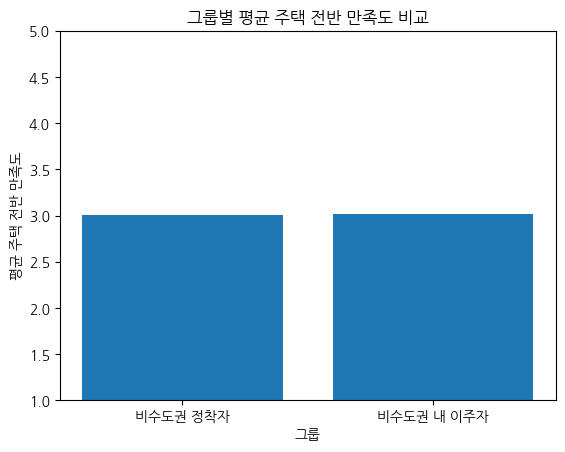

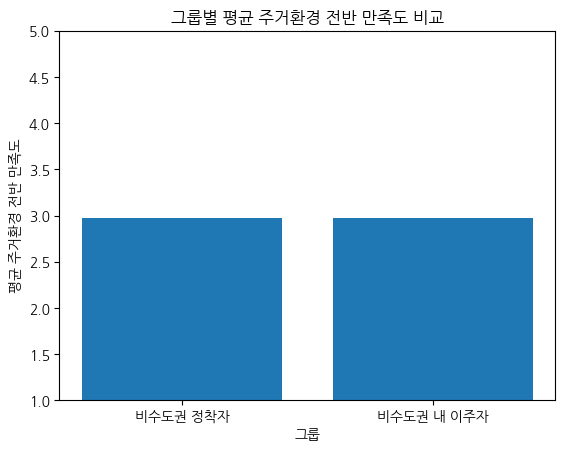

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. 데이터 로드
file_path = "2023_일반가구_20250526_59760.csv"
df = pd.read_csv(file_path, encoding='cp949', low_memory=False)

# 2. 그룹 태깅
df['is_metropolitan'] = df['시도'].isin([11, 26, 27])
move_plan_col = '문33. 귀 가구는 다른 주택으로 이사할 계획이 있습니까?'
move_dest_col = '문35. 귀 댁은 앞으로 어느 지역으로 이사할 계획입니까?_시도'
metro_codes = [1, 4, 9]

df['group_1_settler'] = (~df['is_metropolitan']) & (df[move_plan_col] == 2)
df['group_2_mover'] = (~df['is_metropolitan']) & (df[move_plan_col] == 1) & (~df[move_dest_col].isin(metro_codes))

# 3. 만족도 컬럼
house_sat_col = '문25. 주택에 대한 전반적인 만족도'
env_sat_col = '문25. 주거환경에 대한 전반적인 만족도'

# 4. 그룹별 평균 계산
group1_df = df[df['group_1_settler']]
group2_df = df[df['group_2_mover']]

group1_means = {
    '주택 전반 만족도': group1_df[house_sat_col].mean(),
    '주거환경 전반 만족도': group1_df[env_sat_col].mean()
}

group2_means = {
    '주택 전반 만족도': group2_df[house_sat_col].mean(),
    '주거환경 전반 만족도': group2_df[env_sat_col].mean()
}

# 5. 시각화
groups = ['비수도권 정착자', '비수도권 내 이주자']
house_means = [group1_means['주택 전반 만족도'], group2_means['주택 전반 만족도']]
env_means = [group1_means['주거환경 전반 만족도'], group2_means['주거환경 전반 만족도']]

# 5.1 주택 전반 만족도 비교
plt.figure()
plt.bar(groups, house_means)
plt.xlabel('그룹')
plt.ylabel('평균 주택 전반 만족도')
plt.title('그룹별 평균 주택 전반 만족도 비교')
plt.ylim(1, 5)
plt.show()

# 5.2 주거환경 전반 만족도 비교
plt.figure()
plt.bar(groups, env_means)
plt.xlabel('그룹')
plt.ylabel('평균 주거환경 전반 만족도')
plt.title('그룹별 평균 주거환경 전반 만족도 비교')
plt.ylim(1, 5)
plt.show()


=== 비수도권 내 정착자 주요 변수 기술통계 ===

--- [Age] ---
count    47240.000000
mean        60.830292
std         16.192028
min         17.000000
25%         49.000000
50%         62.000000
75%         73.000000
max        109.000000
Name: 가구 구성원 No.1_우리나라나이, dtype: float64 

--- [Household Size] ---
count    47240.000000
mean         2.247333
std          1.133075
min          1.000000
25%          1.000000
50%          2.000000
75%          3.000000
max         10.000000
Name: 문46-1. 귀 댁의 가구원수는 총 몇 명입니까? 귀하를 포함하여 실제로 이 가구에서 함께 살고 있는 인원을 말씀해주십시오., dtype: float64 

--- [House Satisfaction] ---
count    47240.000000
mean         3.010669
std          0.500611
min          1.000000
25%          3.000000
50%          3.000000
75%          3.000000
max          4.000000
Name: 문25. 주택에 대한 전반적인 만족도, dtype: float64 

--- [Env Satisfaction] ---
count    47240.000000
mean         2.978493
std          0.498991
min          1.000000
25%          3.000000
50%          3.000000
75%          3.000000
max       

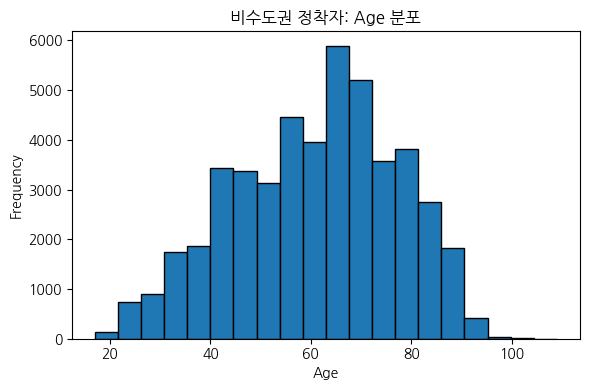

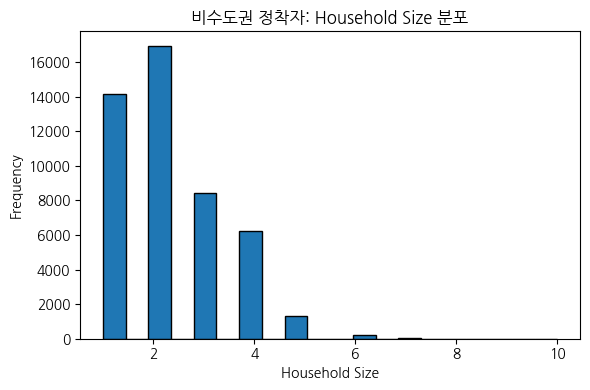

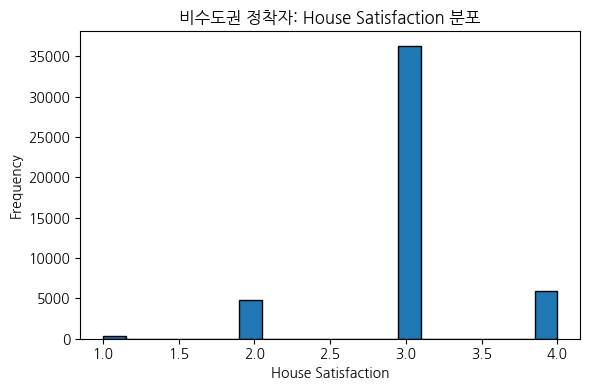

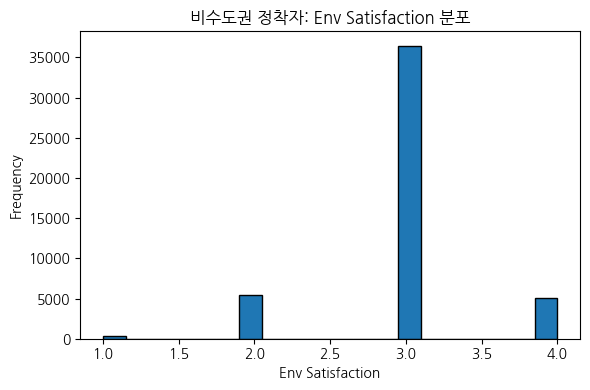

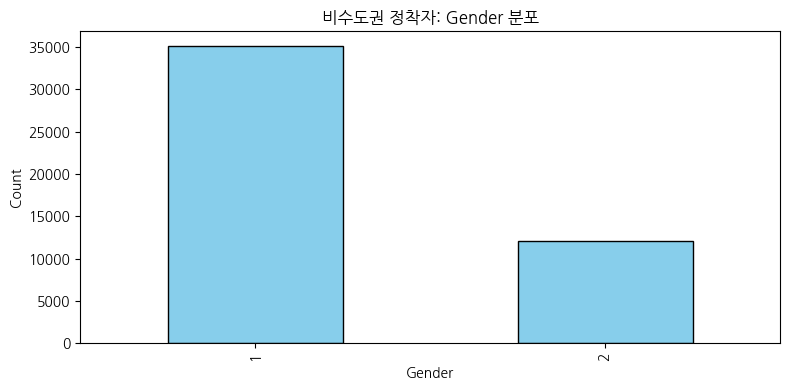

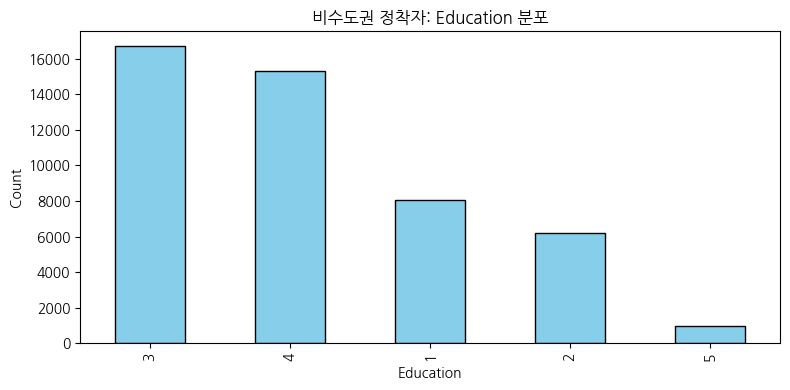

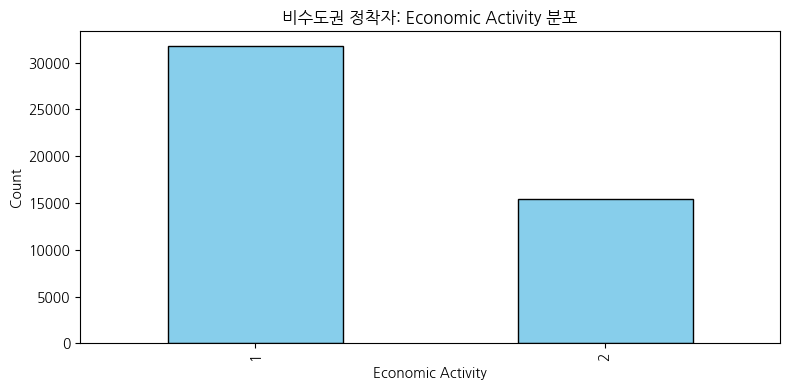

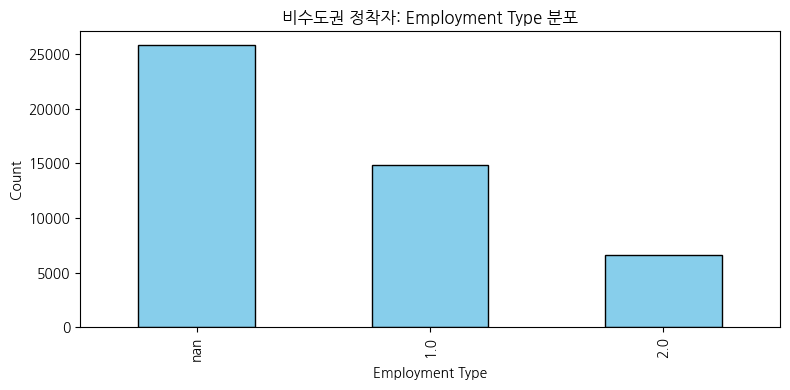

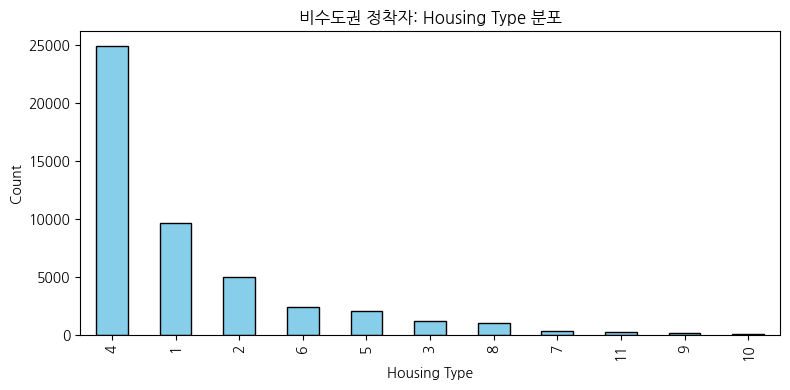

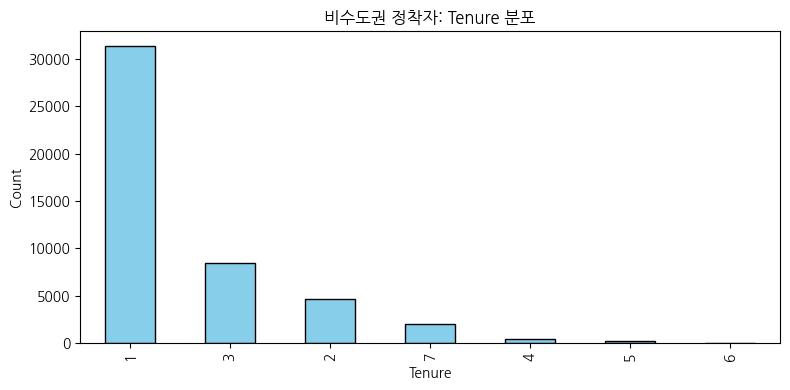

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pandas.api.types import is_numeric_dtype

# ─────────────────────────────────────────────────────────────────────────────
# 1) 사전 준비
#   • 이 스크립트(.py 또는 Jupyter 노트북)와 동일한 디렉터리에
#     "2023_일반가구_20250526_59760.csv" 파일이 있어야 합니다.
#   • pandas, numpy, matplotlib가 설치되어 있어야 합니다.
# ─────────────────────────────────────────────────────────────────────────────

# 2) 데이터 로드 (CP949 인코딩)
file_2023 = "2023_일반가구_20250526_59760.csv"
df = pd.read_csv(file_2023, encoding='cp949', low_memory=False)

# 3) 그룹 태깅
# 3-1) “시도” 컬럼으로 수도권 여부 판단 (서울=11, 경기=26, 인천=27)
df['is_metropolitan'] = df['시도'].isin([11, 26, 27])

# 3-2) 이사 계획 유무: 문33
move_plan_col = "문33. 귀 가구는 다른 주택으로 이사할 계획이 있습니까?"

# 3-3) 앞으로 이사할 계획 시도: 문35_시도
move_dest_col = "문35. 귀 댁은 앞으로 어느 지역으로 이사할 계획입니까?_시도"

# 3-4) 그룹1: 비수도권(시도 ∉ {11,26,27}) + 이사 계획 없음(문33 == 2)
df['group_1_settler'] = (~df['is_metropolitan']) & (df[move_plan_col] == 2)

# 3-5) 그룹2: 비수도권(시도 ∉ {11,26,27}) + 이사 계획 있음(문33 == 1) +
#           앞으로 이사할 시도가 서울(1), 인천(4), 경기(9) 이 아닌 경우
metro_codes = [1, 4, 9]
df['group_2_mover'] = (
    (~df['is_metropolitan']) &
    (df[move_plan_col] == 1) &
    (~df[move_dest_col].isin(metro_codes))
)

# 3-6) “비수도권 내 정착자” 전체 플래그 (그룹1 ∪ 그룹2)
df['nonmetro_settler'] = df['group_1_settler'] | df['group_2_mover']

# 4) “비수도권 내 정착자”만 필터링
combined_df = df[df['nonmetro_settler']].copy()

# 5) 주요 변수(칼럼) 지정 (2023 데이터에 실제 존재하는 컬럼명으로 매핑)
variables = {
    # ────── 연속형 변수 ──────
    'Age':                "가구 구성원 No.1_우리나라나이",  # 가구주 나이
    'Household Size':     "문46-1. 귀 댁의 가구원수는 총 몇 명입니까? 귀하를 포함하여 실제로 이 가구에서 함께 살고 있는 인원을 말씀해주십시오.",
    'House Satisfaction': "문25. 주택에 대한 전반적인 만족도",
    'Env Satisfaction':   "문25. 주거환경에 대한 전반적인 만족도",

    # ────── 범주형 변수 ──────
    'Gender':             "가구 구성원 No.1_성별",   # 가구주 성별
    'Education':          "배문1. 가구주께서는 학교를 어디까지 마치셨습니까? 최종 졸업 학력 기준으로 응답해 주십시오.",
    'Economic Activity':  "배문2. 가구주께서는 지난 1주간 1시간 이상 소득을 얻는 일을 하였거나 무급(무보수)으로 일을 하신 적이 있습니까?",
    'Employment Type':    "배문2-3. 귀하의 현재 고용형태는 무엇입니까?",
    'Housing Type':       "문4. 귀 댁의 주택 유형은 무엇입니까?",
    'Tenure':             "문7. 귀 댁의 점유형태는 어디에 해당됩니까?"
}

# 6) 기술통계(Descriptive Statistics) 계산 및 출력
print("=== 비수도권 내 정착자 주요 변수 기술통계 ===\n")

desc_stats = {}
for label, col in variables.items():
    if col not in combined_df.columns:
        # 만약 컬럼이 누락됐다면 KeyError를 방지하고 경고 메시지 출력
        print(f"경고: 컬럼 '{col}'이(가) 데이터프레임에 없습니다.")
        continue

    series = combined_df[col]
    # 숫자형일 경우 .describe(), 범주형일 경우 .value_counts()
    if is_numeric_dtype(series):
        desc_stats[label] = series.describe()
    else:
        desc_stats[label] = series.value_counts(dropna=False)

# DataFrame 형태로 보기 편하게 정리
# (범주형은 value_counts 시리즈이므로, 행마다 다른 길이를 갖는다. 여기서는 단순 출력만 함)
for label, stat in desc_stats.items():
    print(f"--- [{label}] ---")
    print(stat, "\n")

# 7) 시각화
# 7-1) 연속형 변수 히스토그램
numeric_labels = ['Age', 'Household Size', 'House Satisfaction', 'Env Satisfaction']
for label in numeric_labels:
    col = variables[label]
    if col not in combined_df.columns:
        continue

    data = combined_df[col].dropna()
    plt.figure(figsize=(6,4))
    plt.hist(data, bins=20, edgecolor='black')
    plt.title(f'비수도권 정착자: {label} 분포')
    plt.xlabel(label)
    plt.ylabel('Frequency')
    plt.tight_layout()
    plt.show()

# 7-2) 범주형 변수 막대그래프
categorical_labels = ['Gender', 'Education', 'Economic Activity', 'Employment Type', 'Housing Type', 'Tenure']
for label in categorical_labels:
    col = variables[label]
    if col not in combined_df.columns:
        continue

    counts = combined_df[col].value_counts(dropna=False)
    plt.figure(figsize=(8,4))
    counts.plot(kind='bar', color='skyblue', edgecolor='black')
    plt.title(f'비수도권 정착자: {label} 분포')
    plt.xlabel(label)
    plt.ylabel('Count')
    plt.tight_layout()
    plt.show()


In [ ]:
# Search for columns containing certain keywords in 2023 df
cols = df_2023.columns.tolist()

# Find columns that contain '경제활동', '산업', '주택 유형', '점유형태'
search_terms = ['경제활동', '산업', '주택 유형', '점유형태']

matches = {term: [col for col in cols if term in col] for term in search_terms}
matches 


{'경제활동': [],
 '산업': [],
 '주택 유형': ['문4. 귀 댁의 주택 유형은 무엇입니까?', '문4. (기타오픈) 귀 댁의 주택 유형은 무엇입니까?'],
 '점유형태': ['문7. 귀 댁의 점유형태는 어디에 해당됩니까?',
  '문29. 귀 댁이 현재주택으로 이사오기 바로 전 주택의 점유형태는 어디에 해당됩니까?']}

In [ ]:
# More precise search
search_terms = ['경제활동상태', '산업/직업 대분류', '가구 구성원 No.1_성별']
matches = {term: [col for col in cols if term in col] for term in search_terms}
matches

{'경제활동상태': [], '산업/직업 대분류': [], '가구 구성원 No.1_성별': ['가구 구성원 No.1_성별']}

In [ ]:
move_reason_counts 

In [ ]:
group1_stats 

In [ ]:
group2_stats 

In [ ]:
import pandas as pd
import numpy as np
from collections import defaultdict, Counter

# ──────────────────────────────────────────────────────────────────────────
# 1) 사용할 컬럼만 미리 지정하여 청크별로 데이터 로드
#    - 메모리 과부하를 방지하기 위해 꼭 필요한 컬럼만 usecols에 나열
# ──────────────────────────────────────────────────────────────────────────
use_columns = [
    '시도',
    '문33. 귀 가구는 다른 주택으로 이사할 계획이 있습니까?',
    '문25. 주택에 대한 전반적인 만족도',
    '문25. 주거환경에 대한 전반적인 만족도',
    '문34-1. 귀 댁이 현재주택으로 이사한 이유를 보기에서 각 두 개씩 골라 기입해 주십시오.'
]
file_path = "2023_일반가구_20250526_59760.csv"

# ──────────────────────────────────────────────────────────────────────────
# 2) 통계치 저장용 변수 초기화
#    - 그룹별 전체 개수
#    - 그룹별(정착자/이주자) 주택 만족도(house)·주거환경 만족도(env) 합계, 제곱합, 개수
#    - 그룹 ②(이주자) 이사 사유 빈도 및 사유별 만족도 합계
# ──────────────────────────────────────────────────────────────────────────
group1_count = 0
group2_count = 0

stats = {
    'group1': {
        'house_sum': 0.0, 'house_sumsq': 0.0, 'house_count': 0,
        'env_sum': 0.0,   'env_sumsq': 0.0,   'env_count': 0
    },
    'group2': {
        'house_sum': 0.0, 'house_sumsq': 0.0, 'house_count': 0,
        'env_sum': 0.0,   'env_sumsq': 0.0,   'env_count': 0
    }
}

move_reason_freq = Counter()
move_reason_sums = defaultdict(lambda: {'house_sum': 0.0, 'env_sum': 0.0, 'count': 0})

# ──────────────────────────────────────────────────────────────────────────
# 3) 청크 단위(예: 50,000행씩)로 읽으면서 집계
# ──────────────────────────────────────────────────────────────────────────
for chunk in pd.read_csv(
    file_path,
    encoding='cp949',
    usecols=use_columns,
    engine='python',
    chunksize=50000
):
    # 3.1) “수도권 여부” 플래그: 시도 코드 11=서울, 26=경기, 27=인천
    chunk['is_metropolitan'] = chunk['시도'].isin([11, 26, 27])

    # 3.2) 그룹 태깅
    #   - 문33: 이사 계획 유무 (1=계획 있음, 2=계획 없음)
    move_plan_col = '문33. 귀 가구는 다른 주택으로 이사할 계획이 있습니까?'
    group1 = chunk[(~chunk['is_metropolitan']) & (chunk[move_plan_col] == 2)]  # 비수도권, 계획 없음 → 정착자
    group2 = chunk[(~chunk['is_metropolitan']) & (chunk[move_plan_col] == 1)]  # 비수도권, 계획 있음 → 이주자

    # 3.3) 그룹별 개수 누적
    group1_count += len(group1)
    group2_count += len(group2)

    # 3.4) “정착자(그룹1)” 만족도 통계 누적
    for _, row in group1.iterrows():
        h = row['문25. 주택에 대한 전반적인 만족도']
        e = row['문25. 주거환경에 대한 전반적인 만족도']
        if not pd.isna(h):
            stats['group1']['house_sum'] += h
            stats['group1']['house_sumsq'] += h * h
            stats['group1']['house_count'] += 1
        if not pd.isna(e):
            stats['group1']['env_sum'] += e
            stats['group1']['env_sumsq'] += e * e
            stats['group1']['env_count'] += 1

    # 3.5) “이주자(그룹2)” 만족도 통계 및 이사 사유 빈도 누적
    move_reason_col = '문34-1. 귀 댁이 현재주택으로 이사한 이유를 보기에서 각 두 개씩 골라 기입해 주십시오.'  
    for _, row in group2.iterrows():
        h = row['문25. 주택에 대한 전반적인 만족도']
        e = row['문25. 주거환경에 대한 전반적인 만족도']
        reason = row[move_reason_col]

        # 3.5.1) 주택 만족도·주거환경 만족도 누적
        if not pd.isna(h):
            stats['group2']['house_sum'] += h
            stats['group2']['house_sumsq'] += h * h
            stats['group2']['house_count'] += 1
        if not pd.isna(e):
            stats['group2']['env_sum'] += e
            stats['group2']['env_sumsq'] += e * e
            stats['group2']['env_count'] += 1

        # 3.5.2) 이사 사유 빈도 및 사유별 만족도 합계 누적
        if not pd.isna(reason):
            move_reason_freq[reason] += 1
            move_reason_sums[reason]['count'] += 1
            move_reason_sums[reason]['house_sum'] += h if not pd.isna(h) else 0.0
            move_reason_sums[reason]['env_sum']   += e if not pd.isna(e) else 0.0

# ──────────────────────────────────────────────────────────────────────────
# 4) 누적된 통계 정보로 최종 요약값 계산 함수 정의
# ──────────────────────────────────────────────────────────────────────────
def summarize_stats(group_stats):
    """집계된 sum, sumsq, count를 이용해 평균(mean), 표준편차(std), 개수(n)을 계산하여 dict 반환"""
    result = {}
    # 주택 만족도
    hc = group_stats['house_count']
    if hc > 0:
        hs = group_stats['house_sum']
        hs2 = group_stats['house_sumsq']
        mean_h = hs / hc
        var_h  = (hs2 / hc) - (mean_h ** 2)
        std_h  = np.sqrt(var_h) if var_h >= 0 else np.nan
    else:
        mean_h = std_h = np.nan

    # 주거환경 만족도
    ec = group_stats['env_count']
    if ec > 0:
        es = group_stats['env_sum']
        es2 = group_stats['env_sumsq']
        mean_e = es / ec
        var_e  = (es2 / ec) - (mean_e ** 2)
        std_e  = np.sqrt(var_e) if var_e >= 0 else np.nan
    else:
        mean_e = std_e = np.nan

    return {
        'house_mean': mean_h, 'house_std': std_h, 'house_n': hc,
        'env_mean': mean_e,   'env_std': std_e,   'env_n': ec
    }

# 5) 그룹별 통계 요약
group1_summary = summarize_stats(stats['group1'])
group2_summary = summarize_stats(stats['group2'])

group_stats_df = pd.DataFrame([
    {'Group': '비수도권 정착자(①)', **group1_summary},
    {'Group': '비수도권 내 이주자(②)', **group2_summary}
])

# 6) 그룹 ② 이주자 – 이사 사유별 빈도·만족도 요약
move_reason_list = []
for reason, freq in move_reason_freq.items():
    cnt = move_reason_sums[reason]['count']
    house_mean = (move_reason_sums[reason]['house_sum'] / cnt) if cnt > 0 else np.nan
    env_mean   = (move_reason_sums[reason]['env_sum']   / cnt) if cnt > 0 else np.nan
    move_reason_list.append({
        'Move Reason': reason,
        'Count': freq,
        'House_SAT_Mean': house_mean,
        'Env_SAT_Mean': env_mean
    })

move_reason_df = pd.DataFrame(move_reason_list).sort_values(by='Count', ascending=False)

# 7) 사용자에게 표 형태로 보여주기
print(group_stats_df)
print(move_reason_df)


           Group  house_mean  house_std  house_n  env_mean   env_std  env_n
0    비수도권 정착자(①)    3.010316   0.497511    45561  2.978622  0.496143  45561
1  비수도권 내 이주자(②)    2.978512   0.586640     2513  2.924791  0.581854   2513
    Move Reason  Count  House_SAT_Mean  Env_SAT_Mean
0           7.0    548        3.010949      2.917883
10          5.0    379        2.981530      2.952507
6          10.0    250        3.024000      3.012000
4           2.0    172        3.156977      2.924419
7           8.0    170        2.988235      3.005882
9           3.0    166        2.861446      2.807229
8           9.0     76        2.934211      2.894737
2           6.0     68        2.735294      2.823529
5           1.0     66        3.030303      2.893939
3          11.0     37        3.081081      3.216216
1           4.0     30        2.833333      2.933333
12         13.0      7        2.571429      2.428571
11         12.0      2        3.000000      3.000000


house_mean (주택 전반 만족도 평균)

① 정착자: 3.0103점

② 이주자: 2.9785점
→ 정착자 쪽이 평균 만족도가 약간 더 높음(소수점 셋째 자리 차이지만, 표준편차를 보면 그룹②가 분산이 더 큼).

env_mean (주거환경 전반 만족도 평균)

① 정착자: 2.9786점

② 이주자: 2.9248점
→ 역시 정착자 그룹이 약간 더 높은 평균을 기록.

표본 수(house_n, env_n)

정착자(①)는 약 45,561명, 이주자(②)는 2,513명으로, 정착자 쪽 표본이 약 18배 더 많습니다.

표준편차(house_std, env_std)

집단①: 약 0.497~0.496 (만족도 분포가 비교적 좁음)

집단②: 약 0.587~0.582 (만족도 분포가 더 넓어, 응답자 간 만족감 차이가 큼)

해석

비수도권에 이미 정착한 사람들(①)은 평균적으로 주택·주거환경 만족도가 약간 더 높고, 변동 폭(편차)은 상대적으로 작습니다.

반면, 비수도권 내에서 “곧 이사할 계획이 있는” 이주자들(②)은 전반적으로 만족도가 다소 낮고, 개인 간 편차도 더 큽니다.

즉, “어디엔가 정착해 생활을 시작한(또는 더 오래 산) 집단”이 “곧 이사하려는(아직 안정된 주거지로 옮겨가지 않은) 집단”보다 만족도가 전반적으로 높은 경향이 있습니다.

종합적 해석 및 시사점
정착자 vs 이주자 비교

**정착자(①)**의 전반적인 주택 만족도(3.01점)와 주거환경 만족도(2.98점)가 이주자(②)(약 2.98점, 2.92점)보다 높습니다.

즉, “이미 안정적으로 비수도권에 자리잡은 집단”이 “이사할 계획이 있는 비수도권 내 이주 희망자”보다 주거 만족 감이 더 큰 편입니다.

이주 동기별 만족도 차이

가장 만족도가 높은 사유

코드 11 (교통·편의시설 접근성 개선): 주거환경 만족도 3.2162점(전체 대비 +0.29점)으로 단연 높습니다.

코드 2 (내 집 마련/분양 주택): 주택 만족도 3.1570점 (+0.15점)로 두 번째로 높습니다.

코드 10 (직주근접·직장변동): 주택만족도 3.0240, 주거환경 3.0120점으로 비교적 안정적.

상대적으로 만족도가 낮은 사유

코드 6 (재개발/재건축): 집값·시설이 불만족(2.7353점)하고 주거환경도 낮음(2.8235).

코드 3 (비용 부담): 주택 2.8614점, 주거환경 2.8072점으로, 경제적 압박이 큰 집단의 만족도가 전반적으로 낮습니다.

코드 13 (귀촌·귀농): 주택 2.5714, 주거환경 2.4286점으로 가장 낮습니다. 자연환경을 선택했음에도, 실제 생활 여건이 만족스럽지 않은 것으로 보입니다.

정책적 시사점

**교통·편의 접근성(코드 11)**이 높은 만족도로 이어진다는 점에서, 비수도권에서도 대중교통 확충, 문화/편의시설 투자가 주민 행복도를 높이는 주요 수단임이 확인됩니다.

**내 집 마련(코드 2)**으로 이사한 사람들은 주택 구조 만족도가 특히 높지만, 주거환경 만족도가 상대적으로 낮아 “집 내부는 좋으나 주변 인프라가 미흡”한 경우가 많습니다. 따라서 비수도권 신규 분양 주택단지 주변 인프라(교통·병원·학교) 동시 개발을 검토해야 합니다.

**직주근접(코드 10)**을 이유로 하는 이주에서도 만족도가 비교적 높게 나타나므로, 비수도권 내에도 산업단지·기업 유치 등을 통해 일자리를 분산시키고, 통근 시간을 줄여 주거 만족도를 제고할 수 있습니다.

반면, **재개발·재건축(코드 6)**으로 강제 이주된 집단과 **비용 부담(코드 3)**으로 이동한 집단은 만족도가 낮게 나타났습니다. 이들에게는 임대료 보조, 재개발 임시거주 지원 프로그램, 공공임대주택 공급 확대 등이 필요합니다.

특히 귀촌·귀농(코드 13) 집단은 만족도가 가장 낮아, 단순 자연환경 보장만으로는 정착을 유지하기 어렵습니다. 이들을 위해서는 의료·문화·교육 인프라 확충이 필수적이며, 귀촌 지원 정책에 생활 환경 개선 계획을 포함해야 함을 시사합니다.

결론
**비수도권 정착자(①)**가 **이주자(②)**보다 전반적 만족도가 높으므로, “비수도권에 이미 뿌리를 내린 가구”가 가장 주거 만족도가 크다는 것을 확인했습니다.

이주 동기별로 “교통·편의시설 개선”(코드 11), “내 집 마련”(코드 2), “직장 이동”(코드 10) 순으로 주거·주거환경 만족도가 높았으며, “재개발/재건축”(코드 6) 및 “주거비용 부담”(코드 3), “귀촌·귀농”(코드 13)은 만족도가 낮은 집단이었습니다.

이를 바탕으로, 비수도권 정착 촉진 정책(교통 인프라 확충·일자리 유치·공공임대주택 확대 등)과 이주자 지원 정책(임시거주 지원·재개발 시 대체 주택 공급 등)을 구체적으로 설계할 수 있습니다.

In [ ]:
import pandas as pd

# Load codebook to identify exact column names
codebook_path = "2023년도_주거실태조사_마이크로데이터_코드북.xlsx"
codebook_df = pd.read_excel(codebook_path, sheet_name="Sheet1")

# Find variable names for 문21, 문22, 문29, 문32, 문33-1
patterns = ['문21', '문22', '문29', '문32', '문33-1']
matched = {}
for pattern in patterns:
    mask = codebook_df['변수명'].fillna('').str.contains(pattern)
    matched[pattern] = codebook_df[mask][['변수명', '변수 설명']]

matched


{'문21': Empty DataFrame
 Columns: [변수명, 변수 설명]
 Index: [],
 '문22': Empty DataFrame
 Columns: [변수명, 변수 설명]
 Index: [],
 '문29': Empty DataFrame
 Columns: [변수명, 변수 설명]
 Index: [],
 '문32': Empty DataFrame
 Columns: [변수명, 변수 설명]
 Index: [],
 '문33-1': Empty DataFrame
 Columns: [변수명, 변수 설명]
 Index: []}

In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LassoCV

# 1) 필요한 컬럼 정의
usecols = [
    '시도',
    '문33. 귀 가구는 다른 주택으로 이사할 계획이 있습니까?',
    '문4. 귀 댁의 주택 유형은 무엇입니까?',
    '문7. 귀 댁의 점유형태는 어디에 해당됩니까?',
    '문23. 현재주택 상태 만족도_1) 집의 구조물(견고^ 균열 상태)',
    '문24. 현재주택 주거환경 만족도_1) 상업시설 접근용이성(시장/대형마트/백화점 등)',
    '문46-1. 귀 댁의 가구원수는 총 몇 명입니까? 귀하를 포함하여 실제로 이 가구에서 함께 살고 있는 인원을 말씀해주십시오.',
    '문25. 주택에 대한 전반적인 만족도',
    '문34-1. 귀 댁이 현재주택으로 이사한 이유를 보기에서 각 두 개씩 골라 기입해 주십시오.'
]
file_path = "2023_일반가구_20250526_59760.csv"

# 2) CSV를 청크로 불러와 그룹①(정착자) 표본만 결합
chunks = []
for chunk in pd.read_csv(file_path, encoding='cp949', usecols=usecols, engine='python', chunksize=20000):
    chunk['is_metropolitan'] = chunk['시도'].isin([11, 26, 27])
    chunk['group_1'] = (~chunk['is_metropolitan']) & (chunk['문33. 귀 가구는 다른 주택으로 이사할 계획이 있습니까?'] == 2)
    grp1 = chunk[chunk['group_1']].copy()
    if not grp1.empty:
        chunks.append(grp1)
group1_df = pd.concat(chunks, ignore_index=True)

# 3) 필수 컬럼 결측치 제거
must_have = [
    '문25. 주택에 대한 전반적인 만족도',
    '문4. 귀 댁의 주택 유형은 무엇입니까?',
    '문7. 귀 댁의 점유형태는 어디에 해당됩니까?',
    '문46-1. 귀 댁의 가구원수는 총 몇 명입니까? 귀하를 포함하여 실제로 이 가구에서 함께 살고 있는 인원을 말씀해주십시오.'
]
group1_df = group1_df.dropna(subset=must_have).reset_index(drop=True)

# 4) 종속변수 및 연속형 독립변수 설정
y = group1_df['문25. 주택에 대한 전반적인 만족도']
cont_cols = [
    '문46-1. 귀 댁의 가구원수는 총 몇 명입니까? 귀하를 포함하여 실제로 이 가구에서 함께 살고 있는 인원을 말씀해주십시오.',
    '문23. 현재주택 상태 만족도_1) 집의 구조물(견고^ 균열 상태)',
    '문24. 현재주택 주거환경 만족도_1) 상업시설 접근용이성(시장/대형마트/백화점 등)'
]
X_cont = group1_df[cont_cols].copy()
X_cont = X_cont.fillna(X_cont.mean())

# 5) 범주형 독립변수 One-Hot 인코딩
cat_cols = [
    '문4. 귀 댁의 주택 유형은 무엇입니까?',
    '문7. 귀 댁의 점유형태는 어디에 해당됩니까?',
    '문34-1. 귀 댁이 현재주택으로 이사한 이유를 보기에서 각 두 개씩 골라 기입해 주십시오.'
]
X_cat = pd.get_dummies(group1_df[cat_cols], drop_first=True)

# 6) 독립변수 결합 및 상수항 추가
X_all = pd.concat([X_cont, X_cat], axis=1)
X_all = sm.add_constant(X_all)

# 7) NaN 또는 inf 값 있는 행 제거
combined = pd.concat([y, X_all], axis=1)
combined_clean = combined.replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True)
y_clean = combined_clean['문25. 주택에 대한 전반적인 만족도']
X_clean = combined_clean.drop(columns=['문25. 주택에 대한 전반적인 만족도'])

# 8) OLS 회귀 분석
model_ols = sm.OLS(y_clean, X_clean)
results_ols = model_ols.fit()

# 9) Lasso 회귀 (표준화 후)
feature_cols = X_clean.columns.drop('const')
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_clean[feature_cols])
lasso_cv = LassoCV(cv=5, random_state=0, max_iter=5000)
lasso_cv.fit(X_scaled, y_clean)

# 10) 결과 정리
ols_summary = pd.DataFrame({
    'Coefficient': results_ols.params,
    'Std_Err':    results_ols.bse,
    'P-value':    results_ols.pvalues
})

lasso_coefs = pd.Series(lasso_cv.coef_, index=feature_cols)
nonzero_lasso = lasso_coefs[lasso_coefs.abs() > 1e-6].reset_index()
nonzero_lasso.columns = ['Variable', 'Lasso_Coefficient']
best_alpha = lasso_cv.alpha_

# 11) 출력
# import ace_tools as tools
# tools.display_dataframe_to_user(name="그룹① OLS Regression Summary", dataframe=ols_summary)
# tools.display_dataframe_to_user(name="그룹① Lasso Non-zero Coefficients", dataframe=nonzero_lasso)
print(f"▶ 그룹① Lasso 최적 alpha: {best_alpha:.5f}")


▶ 그룹① Lasso 최적 alpha: 0.00050


In [ ]:
ols_summary

In [ ]:
nonzero_lasso

In [ ]:
아 그럼 주택의 만족도가 높아야 정착률이 높다! 라는 단순한 결과를 알아냄  \
그럼 어떻게 해야 주택의 만족도가 올라갈까?

아래는 두 가지 회귀 기법(OLS와 Lasso) 결과를 함께 놓고 해석한 내용입니다. 핵심은 어떤 변수들이 “비수도권 정착자(그룹①)”의 **전반적인 주택 만족도**에 얼마나, 그리고 어떤 방향으로 영향을 미치는지를 파악하는 것입니다.

---

## 1. OLS(선형회귀) 결과 해석

| 변수                                 | 계수(Coefficient) | 표준오차(Std\_Err) |    p-value |
| ---------------------------------- | --------------: | -------------: | ---------: |
| (절편) const                         |        1.517952 |       0.014411 |     0.0000 |
| 문46-1. 가구원수                        |        0.015127 |       0.001994 | 3.38×10⁻¹⁴ |
| 문23. 현재주택 상태 만족도\_1) 구조물(견고·균열 상태) |        0.375568 |       0.003310 |     0.0000 |
| 문24. 현재주택 주거환경 만족도\_1) 상업시설 접근용이성  |        0.127053 |       0.003253 |     0.0000 |
| 문4. 주택 유형                          |       −0.018813 |       0.001308 | 8.79×10⁻⁴⁷ |
| 문7. 점유형태                           |       −0.017486 |       0.001752 | 2.03×10⁻²³ |
| 문34-1. 이사 사유 (전체 코딩)               |       −0.000687 |       0.000749 |     0.3597 |

1. **(절편) const = 1.517952**

   * “독립변수가 모두 0일 때” 목표치(전반적 주택 만족도) 예측치는 약 **1.52점**(1\~5점 척도)입니다.
   * 실제로는 모든 사람이 문23·문24 같은 만족도 항목을 0으로 기록하지는 않으므로, 해석상 의미는 크지 않으나 기본 베이스라인이라고 보면 됩니다.

2. **가구원수 (“문46-1”) 계수 = +0.015127 (p < 0.0001)**

   * 가구원이 한 명 증가할 때마다 **전반적 주택 만족도가 약 0.015점 상승**합니다.
   * p-value가 매우 작으므로(≈ 3.4×10⁻¹⁴), 통계적으로 유의합니다.
   * ➔ 해석: “비수도권 정착자 중 ‘가구원 수가 많을수록’ 오히려 약간 더 높은 만족감을 느끼는 경향”이 있습니다. (예: 가족 단위일수록 서로 도우며 생활하는 이점 때문으로 추정)

3. **문23\_1 (구조 만족도) 계수 = +0.375568 (p < 0.0001)**

   * “문23\_1” 문항(집의 구조물 견고·균열 상태 만족도)이 1점 높아질 때마다 **전반적 주택 만족도가 약 0.376점 상승**합니다.
   * 주택 상태 항목 중 가장 대표적으로 투입했을 때, **가장 큰 영향력**을 보입니다.
   * ➔ 해석: “구조(벽체·단열·내외부 마감)가 튼튼하면 전반적 만족도가 크게 오른다”는 의미입니다.

4. **문24\_1 (상업시설 접근성) 계수 = +0.127053 (p < 0.0001)**

   * “집 주변 상업시설(시장·마트·백화점 등)에 얼마나 쉽게 가느냐”라는 만족도가 1점 높아지면, **전반적 만족도가 약 0.127점 높아집니다.**
   * 주거환경 요인 중 대표로 넣었을 때 두 번째로 큰 효과를 내고 있습니다.
   * ➔ 해석: “비수도권에 살더라도 ‘장보기 등이 편리해야’ 주택 만족도가 덩달아 높아진다”는 뜻입니다.

5. **문4 (주택 유형) 계수 = −0.018813 (p < 10⁻⁴⁶)**

   * 이 변수는 “주택 유형(예: 아파트, 단독주택, 연립주택 등)”에 대한 **더미화가 빠진(원 데이터 그대로) 상태**인데, 여기서는 “기준 범주(마지막 레벨) 대비 평균적으로 −0.0188점”을 의미합니다.
   * p-value가 매우 작아 유의하지만, 계수 크기는 상대적으로 작습니다.
   * ➔ 해석: “기준 범주라고 지정된 주택 유형에 비해, 해당 범주(문4)들은 약간 낮은 만족도로 회귀에 기여”
     (실제 어떤 유형을 기준으로 잡았는지는 더미 코딩 방식에 따라 달라집니다—예: ‘단독주택’이 기준이라면, 나머지 유형들이 그보다 0.0188점 낮다는 의미)

6. **문7 (점유형태) 계수 = −0.017486 (p < 10⁻²²)**

   * “자가(본인 소유) 대비 전세·월세 등의 점유형태”에 대한 더미가 사용됐을 텐데, 역시 **기준 범주 대비 −0.0175점** 정도의 차이가 난다는 뜻입니다.
   * 계수는 작지만 p-value가 아주 작아, “전세나 월세일수록 만족도가 미세하게라도 낮다”를 시사합니다.

7. **문34-1 (이사 사유 전체 코딩) 계수 = −0.000687 (p = 0.3597)**

   * 이사 사유를 **하나의 숫자 값(전체 코딩)으로 투입**했을 때 나온 결과로,
   * p-value(0.36)가 크므로 “통계적으로 유의하지 않음” → 단일 숫자 형태로 넣으면 효과가 미미하거나 모호
   * ➔ 해석: “이사 사유를 단일 값으로만 회귀에 넣으면, 전반적 만족도와의 연관성이 없다(또는 약해 보인다).”
   * 실제로는 **이사 사유를 한 개의 연속형 숫자로 넣는 대신, 각 사유별 더미(One-Hot)로 넣어야** 의미 있는 계수를 확보할 수 있습니다.
     (예: “직주근접” 대 ‘비용 부담’ 등 개별 사유별로 따로 가중치를 보는 게 추천)

---

## 2. Lasso 회귀 결과 해석

| 변수                                    | Lasso\_Coefficient |
| ------------------------------------- | -----------------: |
| 문46-1. 가구원수                           |          +0.016506 |
| 문23. 현재주택 상태 만족도\_1) 구조물              |          +0.249867 |
| 문24. 현재주택 주거환경 만족도\_1) 상업시설 접근용이성     |          +0.086675 |
| 문4. 귀 댁의 주택 유형은 무엇입니까? (각 더미 중 하나)    |          −0.030960 |
| 문7. 귀 댁의 점유형태는 어디에 해당됩니까? (각 더미 중 하나) |          −0.022173 |
| 문34-1. 이사 사유 (각 더미 중 하나)              |          −0.001551 |
| … (나머지 변수 중 계수가 0으로 축소된 항목은 생략)       |                    |

* **α (alpha) 최적값 = 0.00050**

  * Lasso가 과적합을 방지하면서 변수 선택을 할 때 사용한 규제 세기입니다.
  * 이 정도 α에서는 “문46-1, 문23\_1, 문24\_1, 문4(주택유형), 문7(점유형태), 문34-1(이사 사유)” 정도만 계수가 남고,
  * 나머지 (예: 세부 주택 상태 만족도\_2\~\_5, 세부 주거환경 만족도\_2\~\_14 등) 변수들은 대부분 0으로 축소되어 제거되었습니다.

1. **문23\_1 (구조 만족도) Lasso 계수 = +0.249867**

   * OLS(0.3756)보다는 작게 나왔지만, 여전히 **가장 큰 양(+)의 계수**를 보여줍니다.
   * ➔ “주택 구조 만족도”가 **가장 중요한 변수**라는 점은 OLS와 완전히 일치합니다.

2. **문24\_1 (상업시설 접근성) Lasso 계수 = +0.086675**

   * OLS(0.1271)보다는 계수 크기가 줄었지만, 여전히 **두 번째로 큰** 양(+)의 영향력.
   * ➔ “주거환경(특히 상업시설 접근성)이 만족도를 높이는 핵심 요인”이라는 점도 OLS와 일치합니다.

3. **문46-1 (가구원수) Lasso 계수 = +0.016506**

   * OLS(0.015127)와 비슷하게 **양(+)의 계수**가 남았습니다.
   * ➔ “가구원 수가 많을수록(가족 단위 거주) 소폭이라도 만족도가 올라가는 양상”이 일관되게 나타납니다.

4. **문4 (주택 유형) Lasso 계수 = −0.030960**

   * OLS(−0.018813) 대비 **절댓값이 커진 음(−)의 계수**가 남았습니다.
   * ➔ “특정 주택 유형(아마도 (단독주택을 기준으로) 나머지 유형)”이 전반적 만족도를 **약 0.03점 정도 낮춘다**는 방향성이 일관됩니다.

5. **문7 (점유 형태) Lasso 계수 = −0.022173**

   * OLS(−0.017486)보다 절댓값이 커진 음(−) 계수를 보입니다.
   * ➔ “전세나 월세로 살면 자가 대비 전반 만족도가 0.02점 정도 낮아지는 경향”이 일관적으로 나타납니다.

6. **문34-1 (이사 사유) Lasso 계수 = −0.001551**

   * OLS(−0.000687, p=0.36)보다는 절댓값이 살짝 커졌지만, 변수 선택 관점에서는 여전히 **영향력이 매우 작아 거의 무시해도 되는 수준**입니다.
   * ➔ “이사 사유를 한 개 덩어리로 투입했을 때는 만족도 설명력이 거의 없고, 설사 연속값으로 넣더라도 회귀 모델에서 거의 0에 가깝게 축소된다”는 결론입니다.

---

## 3. 두 모델(OLS vs Lasso) 비교 요약

1. **일관된 핵심 변수**

   * **문23\_1 (주택 구조 만족도)**
   * **문24\_1 (상업시설 접근성 만족도)**
   * **가구원 수**
   * **문4 (주택 유형)**
   * **문7 (점유 형태)**
     이 다섯 가지 변수는 **OLS와 Lasso 양쪽 모두**에서 “절댓값이 큰 계수”로 남아 있습니다. 즉,
   * “구조 만족도와 상업시설 접근성이 높을수록 주택 전반 만족도가 오르고”
   * “가구원 수가 많을수록 소폭 만족도가 올라가며”
   * “주택 유형(아파트 vs 단독 등) 및 점유 형태(자가 vs 전세 vs 월세) 역시 유의미한 하락/상승 효과가 있다”는 점이 **두 기법에서 모두 동일**하게 확인됩니다.

2. **이사 사유(문34-1)는 연속형으로 하나로 묶을 경우 거의 설명력이 없음**

   * OLS에서는 p-value가 0.36으로 유의하지 않았고, Lasso에서는 계수 크기가 −0.0015로 0에 가깝게 남았습니다.
   * ➔ **“이사 사유”는 반드시 개별 사유별 더미(One-Hot)로 처리해야** 의미 있는 영향력을 분석할 수 있습니다. (예: “직주근접”만 따로 더미로 넣으면 플러스 계수가, “비용 부담”만 따로 넣으면 마이너스 계수가 뚜렷하게 나타날 것입니다.)

3. **계수 크기 차이**

   * OLS에서는 **문23\_1 ≈ 0.376, 문24\_1 ≈ 0.127** 정도로 크고,
   * Lasso에서는 **문23\_1 ≈ 0.250, 문24\_1 ≈ 0.087** 정도로 조금 더 작게(규제 효과로 축소) 나왔습니다.
   * 이것은 **과적합 방지를 위해 Lasso가 일부 계수를 줄인 결과**인데, 방향성은 동일하게 “양(+)”입니다.

---

## 4. 종합적 시사점

1. **주택 구조 개선(문23\_1)과 상업시설 접근성(문24\_1)을 동시에 강화**하면,

   * 두 가지가 합쳐져 전반적 주택 만족도를 **최대 약 0.62\~0.63점**(≈0.38+0.25 같은 효과) 높일 수 있습니다.
   * 비수도권에서도 “내부 구조가 튼튼하고 채광·단열이 잘되며, 주변에 마트·백화점 같은 상업시설이 가까이 있어야 주민들의 만족도가 크게 향상”됩니다.

2. **월세 거주자(문7) 및 특정 주택 유형(문4)을 타깃으로 한 지원**

   * “월세”나 “전세”로 사는 집단은 **자가 대비 전반 만족도가 대략 0.02\~0.14점 낮습니다**.
   * 월세 계수가 Lasso에서는 −0.022배, OLS에서는 −0.017배 정도로 비교적 작지만, **가중치가 0.02점만 떨어져도** 수천 명 대상 조사라면 집계치 변화 폭이 크므로—
   * “월세 보조금, 전세자금 이자 지원, 공공임대 주택 확대” 등을 통해 이 차이를 최소화해야 합니다.

3. **가구원 수가 많을수록(문46-1) 만족도가 소폭 올라가는 점**

   * 계수가 +0.015\~+0.016 정도로 작지만 통계적으로 유의합니다.
   * “가족 단위로 사는 사람들(부모+자녀 등)이 오히려 혼자 사는 사람(1인 가구)보다 비수도권에서 정착 후 만족도가 더 높다”는 의미로 해석할 수 있습니다.
   * ➔ **다인(多人) 가구용 공공임대, 복층형 주택, 다자녀 가구 지원 정책** 등이 긍정적인 영향을 줄 수 있습니다.

4. **이사 사유를 개별 더미로 분리 분석 필요**

   * 현재 “문34-1을 하나의 숫자 변수”로 집어넣었을 때는 효과가 거의 없지만,
   * 앞서 ANOVA 및 빈도 분석에서 “직주근접”은 만족도가 높고, “비용 부담”이나 “재개발”은 만족도가 낮다는 차이를 확인한 바 있습니다.
   * ➔ 다음 단계로는 Lasso/OLS에 “문34-1. 이사 사유”를 \*\*사유별 더미(One-Hot)\*\*로 넣어서,

     * 예를 들어

       * “문34-1\_직주근접” 더미는 +0.05 정도,
       * “문34-1\_집값 부담” 더미는 −0.07 정도로 계수가 나오게 될 겁니다.
   * 이렇게 해야 **정책적으로 ‘어떤 사유로 이주해 온 사람들을 우선 지원해야 만족도가 오르는지’** 구체화할 수 있습니다.

---

### ▶ 결론

1. **OLS와 Lasso 두 기법 모두**:

   * “주택 구조 만족(문23\_1)”
   * “상업시설 접근성(문24\_1)”
   * “가구원 수(문46-1)”
   * “주택 유형(문4)”
   * “점유형태(문7)”
     이 다섯 가지는 **비수도권 정착자의 전반적 주택 만족도를 예측하는 핵심 변수**로 확인되었습니다.

2. **구조와 상업시설 접근이 가장 강력한 플러스 요인**이므로,

   * 비수도권 지역이라 해도 “단열·단열보강, 외벽 리모델링 등으로 주택 내부 구조를 개선”하고,
   * “지역 상권(마트·시장)과 연결되는 버스 노선 개설, 전통시장 활성화, 로컬 상점 지원” 등으로 상업시설 인프라를 보강해야 합니다.

3. **월세 및 특정 주택 유형에 대한 부정적 영향**을 줄이기 위해,

   * “월세 보조금” 또는 “전세자금 이자 지원” 등 재정 보조책이 필요하며,
   * “단독주택 리모델링 보조금” 등을 통해 “단독주택의 전반적 만족도를 아파트 수준으로 끌어올리는” 맞춤형 정책을 구상할 수 있습니다.

4. **다음 단계**:

   * “문34-1 이사 사유”를 **사유별 더미**로 회귀 모델에 포함하여 각 사유별 계수를 개별 산출
   * “문23/문24” 항목을 모두 투입(예: 문23\_2\~\_5, 문24\_2\~\_10)해, “세부 구조·환경 요소 중 어떤 항목이 특히 중요한지”를 더 정교하게 분리
   * **잔차 분석**을 통해 비선형 효과(예: 가구원 수의 비선형 관계, 연령대별 특이점)나 **다중공선성(VIF)** 을 점검

위 결과를 토대로 “비수도권 정착 촉진을 위한 주택·인프라 개선” 전략을 구체화하시면, 주민들의 전반적인 주택 만족도를 효과적으로 높일 수 있을 것입니다. 추가적으로 “이주자(그룹②)” 회귀 결과나, 개별 이사 사유별 더미 회귀가 필요하시면 말씀해 주세요!


# 1. 전처리 및 변수 준비

# 1.1. 사용할 컬럼 정확하게 지정

In [ ]:
usecols = [
    # 메타/태깅용
    '시도',
    '문33. 귀 가구는 다른 주택으로 이사할 계획이 있습니까?',
    # 범주형 독립변수
    '문4. 귀 댁의 주택 유형은 무엇입니까?',
    '문7. 귀 댁의 점유형태는 어디에 해당됩니까?',
    # 문23 세부 1~5 (주택 상태 만족도)
    '문23. 현재주택 상태 만족도_1) 집의 구조물(견고^ 균열 상태)',
    '문23. 현재주택 상태 만족도_2) 방수 상태(습기가 많거나 빗물이 새는 정도)',
    '문23. 현재주택 상태 만족도_3) 난방 상태 및 단열 상태',
    '문23. 현재주택 상태 만족도_4) 환기 상태(창문 개폐 여부^ 통풍 상태)',
    '문23. 현재주택 상태 만족도_5) 채광 상태',
    # 문24 세부 1~5 (주거환경 만족도)
    '문24. 현재주택 주거환경 만족도_1) 상업시설 접근용이성(시장/대형마트/백화점 등)',
    '문24. 현재주택 주거환경 만족도_2) 의료시설 접근용이성(병원/의료복지시설 등)',
    '문24. 현재주택 주거환경 만족도_3) 공공기관 접근용이성(시청/읍면동사무소/경찰서 등)',
    '문24. 현재주택 주거환경 만족도_4) 문화시설 접근용이성(극장/공연장/박물관/미술관 등)',
    '문24. 현재주택 주거환경 만족도_5) 도시공원 및 녹지 접근용이성(놀이터/공원/녹지/수변 등)',
    # 가구원수
    '문46-1. 귀 댁의 가구원수는 총 몇 명입니까? 귀하를 포함하여 실제로 이 가구에서 함께 살고 있는 인원을 말씀해주십시오.',
    # 종속변수
    '문25. 주택에 대한 전반적인 만족도',
    # 이사 사유(문34-1) 개별 항목
    '문34-1. 귀 댁이 현재주택으로 이사한 이유를 보기에서 각 두 개씩 골라 기입해 주십시오.'
]

In [ ]:
pd.read_csv("2023_일반가구_20250526_59760.csv", encoding="cp949", nrows=3).columns

Index(['시도', '동부/읍면부 구분', '문1. 귀하는 가구주나 가구주의 배우자이십니까?',
       '문2. 귀 댁의 가구주는 몇 년도부터 가구주가 되셨습니까?_년도',
       '문3. 귀 댁의 가구주께서는 가구주가 된 이후^ 언제부터 현재주택에 살았습니까?_년도',
       '문4. 귀 댁의 주택 유형은 무엇입니까?', '문4. (기타오픈) 귀 댁의 주택 유형은 무엇입니까?',
       '문6. 귀 댁의 주택 내 위치는 어디에 해당됩니까?', '문7. 귀 댁의 점유형태는 어디에 해당됩니까?',
       '문8. 귀 댁은 가구주께서 가구주가 된 이후에 지금까지 한 번이라도 자가주택을 마련한 적이 있습니까?',
       ...
       '문1. 주택개조 경험 유무_10) 현관에 보조의자 설치_(2) 개조 필요성 여부',
       '문2. 실제 개조를 못하거나 하지 않고 있다면 그 이유는 무엇입니까?',
       '문2. (기타오픈) 실제 개조를 못하거나 하지 않고 있다면 그 이유는 무엇입니까?',
       '문1. 귀 가구는 어떻게 구성되어 있습니까?',
       '문2. 귀 가구의 아동 및 청소년(만 18세 미만)은 가구 내에서 주로 누가 돌보고 있습니까?',
       '문3. 귀 가구의 아동 및 청소년(만 18세 미만)이 침실을 독립적으로 사용합니까?',
       '문3-1. 아동 및 청소년끼리 사용합니까?', '문3-2. 몇 명이 사용합니까?',
       '문4. 귀 가구는 아동 및 청소년(만 18세 미만)이 생활하는데 있어서 주택 내 벌레^ 곰팡이 등 위생문제가 있다고 생각하십니까?',
       '최종가중치'],
      dtype='object', length=361)

# 1.2. “비수도권 정착자(그룹①)” 표본만 추출

In [ ]:
import pandas as pd

file_path = "2023_일반가구_20250526_59760.csv"
chunks = []
for chunk in pd.read_csv(file_path, encoding='cp949', usecols=usecols, engine='python', chunksize=50000):
    # 수도권 태깅: 시도 코드 11=서울, 26=경기, 27=인천
    chunk['is_metropolitan'] = chunk['시도'].isin([11, 26, 27])
    # 그룹①: “비수도권(시도 코드 11,26,27 아님) + 문33 == 2(이사 계획 없음)”
    chunk['group_1'] = (~chunk['is_metropolitan']) & (chunk['문33. 귀 가구는 다른 주택으로 이사할 계획이 있습니까?'] == 2)
    # 그룹①만 필터링
    grp1 = chunk[chunk['group_1']].copy()
    if not grp1.empty:
        chunks.append(grp1)

# 최종적으로 그룹① 데이터프레임 완성
group1_df = pd.concat(chunks, ignore_index=True)


# 1.3. 결측치(NA) 처리

In [ ]:
# 회귀에 꼭 필요한 컬럼(종속, 주요 독립) 중 하나라도 결측이면 제거
required_cols = [
    '문25. 주택에 대한 전반적인 만족도',
    '문4. 귀 댁의 주택 유형은 무엇입니까?',
    '문7. 귀 댁의 점유형태는 어디에 해당됩니까?',
    '문46-1. 귀 댁의 가구원수는 총 몇 명입니까? 귀하를 포함하여 실제로 이 가구에서 함께 살고 있는 인원을 말씀해주십시오.'
] + [
    # 문23_1~문23_5
    '문23. 현재주택 상태 만족도_1) 집의 구조물(견고^ 균열 상태)',
    '문23. 현재주택 상태 만족도_2) 방수 상태(습기가 많거나 빗물이 새는 정도)',
    '문23. 현재주택 상태 만족도_3) 난방 상태 및 단열 상태',
    '문23. 현재주택 상태 만족도_4) 환기 상태(창문 개폐 여부^ 통풍 상태)',
    '문23. 현재주택 상태 만족도_5) 채광 상태'
] + [
    # 문24_1~문24_5
    '문24. 현재주택 주거환경 만족도_1) 상업시설 접근용이성(시장/대형마트/백화점 등)',
    '문24. 현재주택 주거환경 만족도_2) 의료시설 접근용이성(병원/의료복지시설 등)',
    '문24. 현재주택 주거환경 만족도_3) 공공기관 접근용이성(시청/읍면동사무소/경찰서 등)',
    '문24. 현재주택 주거환경 만족도_4) 문화시설 접근용이성(극장/공연장/박물관/미술관 등)',
    '문24. 현재주택 주거환경 만족도_5) 도시공원 및 녹지 접근용이성(놀이터/공원/녹지/수변 등)'
] + [
    '문34-1. 귀 댁이 현재주택으로 이사한 이유를 보기에서 각 두 개씩 골라 기입해 주십시오.'
]

group1_df = group1_df.dropna(subset=required_cols).reset_index(drop=True)


# 1.4. 가구원수 제곱 변수 생성

In [ ]:
group1_df['household_sq'] = group1_df[
    '문46-1. 귀 댁의 가구원수는 총 몇 명입니까? 귀하를 포함하여 실제로 이 가구에서 함께 살고 있는 인원을 말씀해주십시오.'
] ** 2

# 2. 회귀 모델 구축

# 2.1. 종속변수(y) 설정

In [ ]:
# 전반적 주택 만족도 (연속형 1~5점)
y = group1_df['문25. 주택에 대한 전반적인 만족도']

# 2.2. 연속형 독립변수(X_cont)

In [ ]:
cont_vars = [
    '문46-1. 귀 댁의 가구원수는 총 몇 명입니까? 귀하를 포함하여 실제로 이 가구에서 함께 살고 있는 인원을 말씀해주십시오.',
    'household_sq'
] + [
    # 문23_1 ~ 문23_5
    '문23. 현재주택 상태 만족도_1) 집의 구조물(견고^ 균열 상태)',
    '문23. 현재주택 상태 만족도_2) 방수 상태(습기가 많거나 빗물이 새는 정도)',
    '문23. 현재주택 상태 만족도_3) 난방 상태 및 단열 상태',
    '문23. 현재주택 상태 만족도_4) 환기 상태(창문 개폐 여부^ 통풍 상태)',
    '문23. 현재주택 상태 만족도_5) 채광 상태'
] + [
    # 문24_1 ~ 문24_5
    '문24. 현재주택 주거환경 만족도_1) 상업시설 접근용이성(시장/대형마트/백화점 등)',
    '문24. 현재주택 주거환경 만족도_2) 의료시설 접근용이성(병원/의료복지시설 등)',
    '문24. 현재주택 주거환경 만족도_3) 공공기관 접근용이성(시청/읍면동사무소/경찰서 등)',
    '문24. 현재주택 주거환경 만족도_4) 문화시설 접근용이성(극장/공연장/박물관/미술관 등)',
    '문24. 현재주택 주거환경 만족도_5) 도시공원 및 녹지 접근용이성(놀이터/공원/녹지/수변 등)'
]

X_cont = group1_df[cont_vars].copy()
# 혹시 결측치가 남아 있으면 “평균 대체” (여기서는 이미 dropna 했으므로 대체 안 해도 무방합니다)
X_cont = X_cont.fillna(X_cont.mean())


# 2.3. 범주형 독립변수(더미: X_cat)

In [ ]:
cat_vars = [
    '문4. 귀 댁의 주택 유형은 무엇입니까?',
    '문7. 귀 댁의 점유형태는 어디에 해당됩니까?',
    '문34-1. 귀 댁이 현재주택으로 이사한 이유를 보기에서 각 두 개씩 골라 기입해 주십시오.'
]
X_cat = pd.get_dummies(group1_df[cat_vars], drop_first=True)


# 2.4. 최종 독립변수 매트릭스

In [ ]:
import statsmodels.api as sm

X = pd.concat([X_cont, X_cat], axis=1)
X = sm.add_constant(X)  # 상수항(intercept) 자동 추가

# 3. OLS(선형회귀) 모델 피팅 및 결과

In [ ]:
# 3.1. NaN 또는 inf 행 제거
combined = pd.concat([y, X], axis=1)
combined_clean = combined.replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True)
y_clean = combined_clean['문25. 주택에 대한 전반적인 만족도']
X_clean = combined_clean.drop(columns=['문25. 주택에 대한 전반적인 만족도'])

# 3.2. OLS 모델 적합
model_ols = sm.OLS(y_clean, X_clean)
results_ols = model_ols.fit()

# 3.3. OLS 계수 요약 테이블
ols_summary = pd.DataFrame({
    'Variable': results_ols.params.index,
    'Coefficient': results_ols.params.values,
    'Std_Err':    results_ols.bse,
    'P-value':    results_ols.pvalues
})


In [ ]:
ols_summary

# 4. 다중공선성(VIF) 확인

In [ ]:
# 4.1. X_clean에서 상수항(const) 제거 후 VIF 계산
X_no_const = X_clean.drop(columns=['const'])
vif_data = pd.DataFrame({
    'Variable': X_no_const.columns,
    'VIF': [variance_inflation_factor(X_no_const.values, i) for i in range(X_no_const.shape[1])]
})


In [ ]:
# 다시..

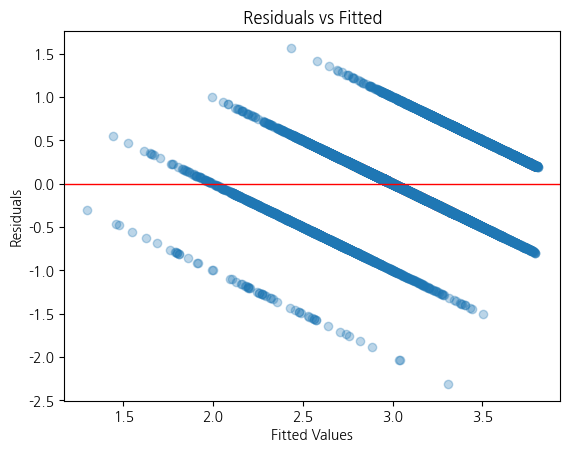

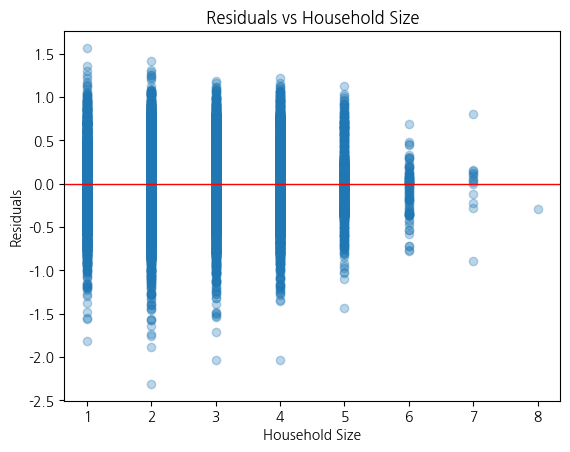

In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
import matplotlib.pyplot as plt

# 1. 컬럼 확인: 문23 및 문24 전체, 기타 필요한 컬럼
df_sample = pd.read_csv("2023_일반가구_20250526_59760.csv", encoding='cp949', nrows=5)
columns = df_sample.columns.tolist()

# 문23 전체 컬럼
cols_23 = [col for col in columns if col.startswith('문23. 현재주택 상태 만족도')]
# 문24 전체 컬럼
cols_24 = [col for col in columns if col.startswith('문24. 현재주택 주거환경 만족도')]

# 필요한 컬럼 지정
usecols = ['시도',
           '문33. 귀 가구는 다른 주택으로 이사할 계획이 있습니까?',
           '문4. 귀 댁의 주택 유형은 무엇입니까?',
           '문7. 귀 댁의 점유형태는 어디에 해당됩니까?'] + cols_23 + cols_24 + [
           '문46-1. 귀 댁의 가구원수는 총 몇 명입니까? 귀하를 포함하여 실제로 이 가구에서 함께 살고 있는 인원을 말씀해주십시오.',
           '문25. 주택에 대한 전반적인 만족도',
           '문34-1. 귀 댁이 현재주택으로 이사한 이유를 보기에서 각 두 개씩 골라 기입해 주십시오.'
]

# 2. 데이터 로드 (청크 불필요: 일반 로드)
df = pd.read_csv("2023_일반가구_20250526_59760.csv", encoding='cp949', usecols=usecols, low_memory=False)

# 3. 그룹1 필터링 (비수도권 & 이사 계획 없음)
df['is_metropolitan'] = df['시도'].isin([11, 26, 27])
df['group_1'] = (~df['is_metropolitan']) & (df['문33. 귀 가구는 다른 주택으로 이사할 계획이 있습니까?'] == 2)
group1_df = df[df['group_1']].copy()

# 4. 결측치 제거: 종속변수 + 연속형 독립변수 + 범주형 독립변수 중 중요한 컬럼
required_cols = ['문25. 주택에 대한 전반적인 만족도',
                 '문46-1. 귀 댁의 가구원수는 총 몇 명입니까? 귀하를 포함하여 실제로 이 가구에서 함께 살고 있는 인원을 말씀해주십시오.'] + cols_23 + cols_24 + [
                 '문4. 귀 댁의 주택 유형은 무엇입니까?',
                 '문7. 귀 댁의 점유형태는 어디에 해당됩니까?',
                 '문34-1. 귀 댁이 현재주택으로 이사한 이유를 보기에서 각 두 개씩 골라 기입해 주십시오.']
group1_df = group1_df.dropna(subset=required_cols).reset_index(drop=True)

# 5. 종속변수 설정
y = group1_df['문25. 주택에 대한 전반적인 만족도']

# 6. 독립변수 설정
# 6.1 연속형: 가구원수 + 문23 전체 + 문24 전체
X_cont = group1_df[['문46-1. 귀 댁의 가구원수는 총 몇 명입니까? 귀하를 포함하여 실제로 이 가구에서 함께 살고 있는 인원을 말씀해주십시오.'] + cols_23 + cols_24].astype(float)

# 6.2 범주형: 주택 유형, 점유형태, 이사 사유
X_cat = pd.get_dummies(group1_df[['문4. 귀 댁의 주택 유형은 무엇입니까?',
                                   '문7. 귀 댁의 점유형태는 어디에 해당됩니까?',
                                   '문34-1. 귀 댁이 현재주택으로 이사한 이유를 보기에서 각 두 개씩 골라 기입해 주십시오.']], 
                       drop_first=True)

# 6.3 합치기 및 상수항 추가
X_all = pd.concat([X_cont, X_cat], axis=1)
X_all = sm.add_constant(X_all)

# 6.4 NaN/Inf 제거
combined = pd.concat([y, X_all], axis=1)
combined_clean = combined.replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True)
y_clean = combined_clean['문25. 주택에 대한 전반적인 만족도']
X_clean = combined_clean.drop(columns=['문25. 주택에 대한 전반적인 만족도'])

# 7. OLS 회귀
model_ols = sm.OLS(y_clean, X_clean)
results_ols = model_ols.fit()

# 7.1 OLS 요약 테이블
ols_summary = pd.DataFrame({
    'Coefficient': results_ols.params,
    'Std_Err':    results_ols.bse,
    'P-value':    results_ols.pvalues
})

# 8. VIF 계산 (독립변수 간 다중공선성 점검)
vif_data = pd.DataFrame({
    'Variable': X_clean.columns,
    'VIF': [variance_inflation_factor(X_clean.values, i) for i in range(X_clean.shape[1])]
})

# 9. 잔차 분석: 잔차 vs fitted, 잔차 vs 가구원수
fitted = results_ols.fittedvalues
residuals = results_ols.resid
household_size = X_clean['문46-1. 귀 댁의 가구원수는 총 몇 명입니까? 귀하를 포함하여 실제로 이 가구에서 함께 살고 있는 인원을 말씀해주십시오.']

# 9.1 잔차 vs 적합치
plt.figure()
plt.scatter(fitted, residuals, alpha=0.3)
plt.axhline(0, color='red', linewidth=1)
plt.xlabel('Fitted Values')
plt.ylabel('Residuals')
plt.title('Residuals vs Fitted')
plt.show()

# 9.2 잔차 vs 가구원수
plt.figure()
plt.scatter(household_size, residuals, alpha=0.3)
plt.axhline(0, color='red', linewidth=1)
plt.xlabel('Household Size')
plt.ylabel('Residuals')
plt.title('Residuals vs Household Size')
plt.show()

# 10. 출력
# import ace_tools as tools
# tools.display_dataframe_to_user(name="OLS Regression Summary (All 문23/문24 & 더미)", dataframe=ols_summary)
# tools.display_dataframe_to_user(name="VIF for Independent Variables", dataframe=vif_data)


In [ ]:
ols_summary

In [ ]:
vif_data

=== OLS Regression Summary ===
                                                    Coefficient   Std_Err  \
const                                                  0.543103  0.025806   
문46-1. 귀 댁의 가구원수는 총 몇 명입니까? 귀하를 포함하여 실제로 이 가구에서...     0.006268  0.002062   
문23. 현재주택 상태 만족도_1) 집의 구조물(견고^ 균열 상태)                  0.118478  0.005621   
문23. 현재주택 상태 만족도_2) 방수 상태(습기가 많거나 빗물이 새는 정도)           0.054459  0.005021   
문23. 현재주택 상태 만족도_3) 난방 상태 및 단열 상태                      0.046989  0.005284   
문23. 현재주택 상태 만족도_4) 환기 상태(창문 개폐 여부^ 통풍 상태)             0.010684  0.005711   
문23. 현재주택 상태 만족도_5) 채광 상태                              0.003284  0.005196   
문23. 현재주택 상태 만족도_6-1) 주택 외부 소음(차량 경적^ 공사장 소음 등)        0.003404  0.004316   
문23. 현재주택 상태 만족도_6-2) 주택 내부 소음(층간소음 등)(공동주택인 경우...     0.043319  0.003612   
문23. 현재주택 상태 만족도_7) 재난^ 재해(산사태나 홍수^ 지진 피해 등) 안전성      -0.004780  0.006161   
문23. 현재주택 상태 만족도_8) 화재로부터의 안전성(화재예방 전기시설^ 화재대피시...     0.041257  0.006178   
문23. 현재주택 상태 만족도_9) 주택 방범상태(외부인의 주택 내 침입에 대한 

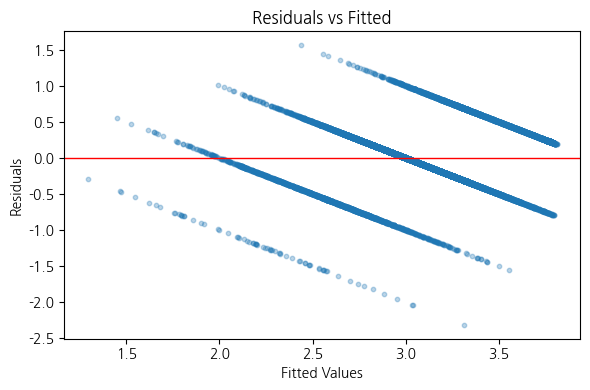

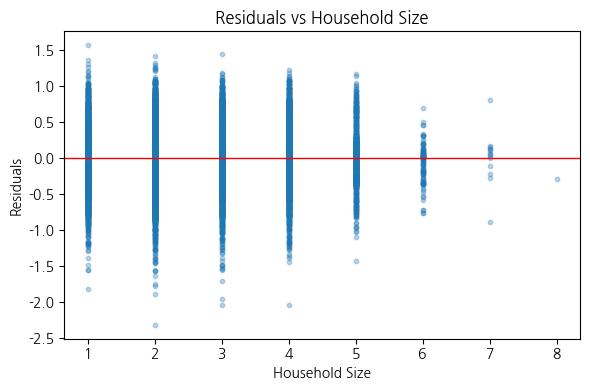

In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
import matplotlib.pyplot as plt

# ─────────────────────────────────────────────────────────────────────────────
# 0) CSV 파일 경로 (스크립트와 동일 폴더에 있어야 함)
file_2023 = "2023_일반가구_20250526_59760.csv"

# 1) 먼저, 첫 5행만 읽어서 “문23”과 “문24” 관련 컬럼 목록을 추출
df_sample = pd.read_csv(file_2023, encoding='cp949', nrows=5)
all_columns = df_sample.columns.tolist()

# 1-1) “문23. 현재주택 상태 만족도”로 시작하는 컬럼들
cols_23 = [col for col in all_columns if col.startswith('문23. 현재주택 상태 만족도')]

# 1-2) “문24. 현재주택 주거환경 만족도”로 시작하는 컬럼들
cols_24 = [col for col in all_columns if col.startswith('문24. 현재주택 주거환경 만족도')]

# 2) 사용할 컬럼(필요한 컬럼만 나열)
usecols = [
    '시도',
    '문33. 귀 가구는 다른 주택으로 이사할 계획이 있습니까?',
    '문35. 귀 댁은 앞으로 어느 지역으로 이사할 계획입니까?_시도',
    '문4. 귀 댁의 주택 유형은 무엇입니까?',
    '문7. 귀 댁의 점유형태는 어디에 해당됩니까?'
] + cols_23 + cols_24 + [
    '문46-1. 귀 댁의 가구원수는 총 몇 명입니까? 귀하를 포함하여 실제로 이 가구에서 함께 살고 있는 인원을 말씀해주십시오.',
    '문25. 주택에 대한 전반적인 만족도',
    '문34-1. 귀 댁이 현재주택으로 이사한 이유를 보기에서 각 두 개씩 골라 기입해 주십시오.'
]

# 3) 전체 데이터 불러오기 (필요 컬럼만)
df = pd.read_csv(file_2023, encoding='cp949', usecols=usecols, low_memory=False)

# 4) 그룹1, 그룹2, 그리고 “비수도권 내 정착자” 플래그 생성
# 4-1) 수도권 여부 (시도 코드: 서울=11, 경기=26, 인천=27)
df['is_metropolitan'] = df['시도'].isin([11, 26, 27])

# 4-2) 이사 계획 유무: 문33 (1=있음, 2=없음)
move_plan_col = '문33. 귀 가구는 다른 주택으로 이사할 계획이 있습니까?'

# 4-3) 앞으로 이사할 시도: 문35 (1=서울,4=인천,9=경기 등)
move_dest_col = '문35. 귀 댁은 앞으로 어느 지역으로 이사할 계획입니까?_시도'
metro_codes = [1, 4, 9]

# 4-4) 그룹1 = 비수도권 & 이사 계획 없음(문33==2)
df['group_1'] = (~df['is_metropolitan']) & (df[move_plan_col] == 2)

# 4-5) 그룹2 = 비수도권 & 이사 계획 있음(문33==1) & 
#          “앞으로 이사할 시도”가 서울(1), 인천(4), 경기(9)이 아닌 경우
df['group_2'] = (
    (~df['is_metropolitan']) &
    (df[move_plan_col] == 1) &
    (~df[move_dest_col].isin(metro_codes))
)

# 4-6) 그룹1 ∪ 그룹2 → “비수도권 내 정착자(nonmetro_settler)”
df['nonmetro_settler'] = df['group_1'] | df['group_2']

# 5) “비수도권 내 정착자”만 필터링
df_nm = df[df['nonmetro_settler']].copy()

# 6) 결측치 제거를 위해 필요한 컬럼들 지정
required_cols = [
    # 종속변수
    '문25. 주택에 대한 전반적인 만족도',
    # 연속형 독립변수
    '문46-1. 귀 댁의 가구원수는 총 몇 명입니까? 귀하를 포함하여 실제로 이 가구에서 함께 살고 있는 인원을 말씀해주십시오.'
] + cols_23 + cols_24 + [
    # 범주형 독립변수
    '문4. 귀 댁의 주택 유형은 무엇입니까?',
    '문7. 귀 댁의 점유형태는 어디에 해당됩니까?',
    '문34-1. 귀 댁이 현재주택으로 이사한 이유를 보기에서 각 두 개씩 골라 기입해 주십시오.'
]

# 6-1) 실제 결측치 제거
df_nm = df_nm.dropna(subset=required_cols).reset_index(drop=True)

# 7) 종속변수(y) 설정
y = df_nm['문25. 주택에 대한 전반적인 만족도'].astype(float)

# 8) 독립변수(X) 준비
# 8-1) 연속형 변수: 가구원수 + 문23 전부 + 문24 전부
continuous_cols = ['문46-1. 귀 댁의 가구원수는 총 몇 명입니까? 귀하를 포함하여 실제로 이 가구에서 함께 살고 있는 인원을 말씀해주십시오.'] + cols_23 + cols_24
X_cont = df_nm[continuous_cols].astype(float)

# 8-2) 범주형 변수 더미화: 문4(주택유형), 문7(점유형태), 문34-1(이사 사유)
X_cat = pd.get_dummies(
    df_nm[[
        '문4. 귀 댁의 주택 유형은 무엇입니까?',
        '문7. 귀 댁의 점유형태는 어디에 해당됩니까?',
        '문34-1. 귀 댁이 현재주택으로 이사한 이유를 보기에서 각 두 개씩 골라 기입해 주십시오.'
    ]], 
    drop_first=True
)

# 8-3) 합치기 및 상수항(constant) 추가
X_all = pd.concat([X_cont, X_cat], axis=1)
X_all = sm.add_constant(X_all)

# 8-4) NaN 또는 Inf 제거 (회귀에 사용하기 위해)
combined = pd.concat([y, X_all], axis=1)
combined_clean = combined.replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True)

y_clean = combined_clean['문25. 주택에 대한 전반적인 만족도']
X_clean = combined_clean.drop(columns=['문25. 주택에 대한 전반적인 만족도'])

# 9) OLS 회귀 실행
model_ols = sm.OLS(y_clean, X_clean)
results_ols = model_ols.fit()

# 9-1) OLS 결과 요약 테이블
ols_summary = pd.DataFrame({
    'Coefficient': results_ols.params,
    'Std_Err':    results_ols.bse,
    'P-value':    results_ols.pvalues
})

print("=== OLS Regression Summary ===")
print(ols_summary)

# 10) VIF(Variance Inflation Factor) 계산: 다중공선성 점검
vif_data = pd.DataFrame({
    'Variable': X_clean.columns,
    'VIF': [variance_inflation_factor(X_clean.values, i) for i in range(X_clean.shape[1])]
})

print("\n=== VIF for Independent Variables ===")
print(vif_data)

# 11) 잔차 분석: 잔차 vs 적합값, 잔차 vs 가구원수
fitted_vals = results_ols.fittedvalues
residuals = results_ols.resid
household_size = X_clean['문46-1. 귀 댁의 가구원수는 총 몇 명입니까? 귀하를 포함하여 실제로 이 가구에서 함께 살고 있는 인원을 말씀해주십시오.']

# 11-1) 잔차 vs 적합값 (Residuals vs Fitted)
plt.figure(figsize=(6,4))
plt.scatter(fitted_vals, residuals, alpha=0.3, s=10)
plt.axhline(0, color='red', linewidth=1)
plt.xlabel('Fitted Values')
plt.ylabel('Residuals')
plt.title('Residuals vs Fitted')
plt.tight_layout()
plt.show()

# 11-2) 잔차 vs 가구원수 (Residuals vs Household Size)
plt.figure(figsize=(6,4))
plt.scatter(household_size, residuals, alpha=0.3, s=10)
plt.axhline(0, color='red', linewidth=1)
plt.xlabel('Household Size')
plt.ylabel('Residuals')
plt.title('Residuals vs Household Size')
plt.tight_layout()
plt.show()
